# Credit Score Classification — Modelling & Experiments

Compare several classifiers on the cleaned data from `01_eda.ipynb`, tune the strongest one, and analyse the results.
Run `01_eda.ipynb` first (it writes `../pipeline/ingested/data_cleaned.csv`).

In [1]:
# ========================================
# 1. IMPORT LIBRARIES
# ========================================
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

RANDOM_STATE = 42
TEST_SIZE = 0.2

## 2. Load Cleaned Data

In [2]:
# ========================================
# 2. LOAD CLEANED DATA
# ========================================
df_clean = pd.read_csv('../pipeline/ingested/data_cleaned.csv')

print(f"Shape: {df_clean.shape}")
print(f"Missing values: {df_clean.isnull().sum().sum()}")
print(f"\nTarget distribution:")
print(df_clean['Credit_Score'].value_counts())

Shape: (25000, 22)
Missing values: 0

Target distribution:
Credit_Score
Standard    13330
Poor         7302
Good         4368
Name: count, dtype: int64


## 3. Model Experimenter

`ModelExperimenter` bundles preprocessing, training and tuning.

**Preprocessing decisions**
- Categorical → LabelEncoder (fine for tree models)
- Numeric → StandardScaler
- Split → stratified 80/20 (the target is imbalanced)

In [3]:
# ========================================
# 3. MODEL EXPERIMENTER CLASS
# ========================================
class ModelExperimenter:
    """Encapsulate training + tuning multiple classification models."""

    def __init__(self, df, target_col='Credit_Score', random_state=42, test_size=0.2):
        self.df = df.copy()
        self.target_col = target_col
        self.random_state = random_state
        self.test_size = test_size

        self.label_encoders = {}
        self.target_encoder = None
        self.scaler = None
        self.X_train = None
        self.X_test = None
        self.y_train = None
        self.y_test = None
        self.feature_columns = None

        self.results = {}
        self.predictions = {}
        self.fitted_models = {}

    def prepare(self):
        """Encode + scale + split."""
        categorical_cols = self.df.select_dtypes(include=['object']).columns.tolist()
        if self.target_col in categorical_cols:
            categorical_cols.remove(self.target_col)

        for col in categorical_cols:
            le = LabelEncoder()
            self.df[col] = le.fit_transform(self.df[col].astype(str))
            self.label_encoders[col] = le

        self.target_encoder = LabelEncoder()
        self.df[self.target_col] = self.target_encoder.fit_transform(self.df[self.target_col])

        X = self.df.drop(columns=[self.target_col])
        y = self.df[self.target_col]
        self.feature_columns = list(X.columns)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=self.test_size,
            random_state=self.random_state, stratify=y
        )

        self.scaler = StandardScaler()
        self.X_train = self.scaler.fit_transform(X_train)
        self.X_test = self.scaler.transform(X_test)
        self.y_train = y_train
        self.y_test = y_test

        print(f"Train set : {self.X_train.shape[0]} rows")
        print(f"Test set  : {self.X_test.shape[0]} rows")
        print(f"Features  : {len(self.feature_columns)}")
        print(f"Target encoding: {dict(zip(self.target_encoder.classes_, self.target_encoder.transform(self.target_encoder.classes_)))}")
        return self

    def _calculate_metrics(self, y_pred):
        return {
            'Accuracy': accuracy_score(self.y_test, y_pred),
            'Precision': precision_score(self.y_test, y_pred, average='macro'),
            'Recall': recall_score(self.y_test, y_pred, average='macro'),
            'F1-Score': f1_score(self.y_test, y_pred, average='macro')
        }

    def train_baselines(self):
        """Train 4 baseline models."""
        models = {
            'Logistic Regression': LogisticRegression(random_state=self.random_state, max_iter=1000),
            'Decision Tree': DecisionTreeClassifier(random_state=self.random_state),
            'Random Forest': RandomForestClassifier(random_state=self.random_state, n_estimators=100),
            'Gradient Boosting': GradientBoostingClassifier(random_state=self.random_state),
        }

        for name, model in models.items():
            model.fit(self.X_train, self.y_train)
            y_pred = model.predict(self.X_test)
            self.predictions[name] = y_pred
            self.fitted_models[name] = model
            self.results[name] = self._calculate_metrics(y_pred)
            print(f"{name:22s} | Acc: {self.results[name]['Accuracy']:.4f} | F1: {self.results[name]['F1-Score']:.4f}")
        return self

    def tune_random_forest(self):
        """Grid-search tuning for Random Forest."""
        param_grid = {
            'n_estimators': [100, 200],
            'max_depth': [10, 20],
            'min_samples_split': [2, 5],
            'min_samples_leaf': [1, 2]
        }

        grid_search = GridSearchCV(
            RandomForestClassifier(random_state=self.random_state),
            param_grid, cv=3, scoring='f1_macro', n_jobs=-1, verbose=1
        )
        grid_search.fit(self.X_train, self.y_train)

        best_rf = grid_search.best_estimator_
        y_pred = best_rf.predict(self.X_test)

        self.fitted_models['Random Forest (Tuned)'] = best_rf
        self.predictions['Random Forest (Tuned)'] = y_pred
        self.results['Random Forest (Tuned)'] = self._calculate_metrics(y_pred)

        print(f"\nBest params: {grid_search.best_params_}")
        print(f"Best CV F1 : {grid_search.best_score_:.4f}")
        print(f"Test F1    : {self.results['Random Forest (Tuned)']['F1-Score']:.4f}")
        return self

In [4]:
# ========================================
# PREPARE DATA
# ========================================
experimenter = ModelExperimenter(df_clean, random_state=RANDOM_STATE, test_size=TEST_SIZE)
experimenter.prepare()

Train set : 20000 rows
Test set  : 5000 rows
Features  : 21
Target encoding: {'Good': np.int64(0), 'Poor': np.int64(1), 'Standard': np.int64(2)}


## 4. Training & Tuning

### 4.1 Baseline Models

Four algorithms are compared:
- **Logistic Regression** — linear, interpretable baseline
- **Decision Tree** — simple non-linear baseline
- **Random Forest** — bagging ensemble, strong on tabular data
- **Gradient Boosting** — boosting ensemble, often the best on tabular data

In [5]:
print("="*50)
print("TRAINING BASELINE MODELS")
print("="*50)
experimenter.train_baselines()

TRAINING BASELINE MODELS


Logistic Regression    | Acc: 0.6108 | F1: 0.5508


Decision Tree          | Acc: 0.6156 | F1: 0.5870


Random Forest          | Acc: 0.7406 | F1: 0.7166


Gradient Boosting      | Acc: 0.7100 | F1: 0.6787


### 4.2 Hyperparameter Tuning

Random Forest is tuned because it was the best baseline, provides `predict_proba` out of the box, and trains quickly.
GridSearchCV with 3-fold CV, scored on `f1_macro`.

In [6]:
print("="*50)
print("HYPERPARAMETER TUNING (Random Forest)")
print("="*50)
experimenter.tune_random_forest()

HYPERPARAMETER TUNING (Random Forest)
Fitting 3 folds for each of 16 candidates, totalling 48 fits



Best params: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1 : 0.6920
Test F1    : 0.7181


## 5. Results

`ResultsAnalyzer` handles comparison tables, plots and the final report.

In [7]:
# ========================================
# 5. RESULTS ANALYZER CLASS
# ========================================
class ResultsAnalyzer:
    """Encapsulate model comparison & reporting."""

    def __init__(self, experimenter):
        self.experimenter = experimenter
        self.comparison_df = pd.DataFrame(experimenter.results).T.round(4)

    def show_comparison_table(self):
        print(self.comparison_df)
        return self.comparison_df

    def plot_comparison(self):
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
        for idx, metric in enumerate(metrics):
            row, col = idx // 2, idx % 2
            self.comparison_df[metric].plot(kind='bar', ax=axes[row, col], color='steelblue')
            axes[row, col].set_title(f'{metric} Comparison', fontweight='bold')
            axes[row, col].set_ylim([0, 1.1])
            axes[row, col].axhline(y=self.comparison_df[metric].mean(), color='red',
                                   linestyle='--', label='Mean')
            axes[row, col].legend()
            axes[row, col].tick_params(axis='x', rotation=45)
        plt.tight_layout()
        plt.show()

    def plot_confusion_matrices(self):
        n_models = len(self.experimenter.predictions)
        n_cols = 3
        n_rows = (n_models + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
        axes = axes.ravel() if n_models > 1 else [axes]
        target_labels = self.experimenter.target_encoder.classes_
        for idx, (name, y_pred) in enumerate(self.experimenter.predictions.items()):
            cm = confusion_matrix(self.experimenter.y_test, y_pred)
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                        xticklabels=target_labels, yticklabels=target_labels)
            axes[idx].set_title(name, fontweight='bold')
            axes[idx].set_ylabel('Actual')
            axes[idx].set_xlabel('Predicted')
        for i in range(len(self.experimenter.predictions), len(axes)):
            axes[i].axis('off')
        plt.tight_layout()
        plt.show()

    def plot_feature_importance(self, model_name='Random Forest (Tuned)'):
        model = self.experimenter.fitted_models[model_name]
        if not hasattr(model, 'feature_importances_'):
            print(f"Model {model_name} has no feature_importances_")
            return
        fi_df = pd.DataFrame({
            'Feature': self.experimenter.feature_columns,
            'Importance': model.feature_importances_
        }).sort_values('Importance', ascending=False)
        plt.figure(figsize=(10, 8))
        plt.barh(fi_df['Feature'], fi_df['Importance'], color='teal')
        plt.xlabel('Importance')
        plt.title(f'Feature Importance - {model_name}', fontweight='bold', fontsize=14)
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.show()
        return fi_df

    def report_best_model(self):
        best_name = self.comparison_df['F1-Score'].idxmax()
        best_metrics = self.comparison_df.loc[best_name]
        print(f"\n{'='*50}")
        print(f"BEST MODEL: {best_name}")
        print(f"{'='*50}")
        for metric, value in best_metrics.items():
            print(f"{metric:12s}: {value:.4f}")
        print(f"\nClassification Report:")
        print(classification_report(
            self.experimenter.y_test,
            self.experimenter.predictions[best_name],
            target_names=self.experimenter.target_encoder.classes_
        ))
        return best_name

In [8]:
analyzer = ResultsAnalyzer(experimenter)
analyzer.show_comparison_table()

                       Accuracy  Precision  Recall  F1-Score
Logistic Regression      0.6108     0.5987  0.5325    0.5508
Decision Tree            0.6156     0.5845  0.5899    0.5870
Random Forest            0.7406     0.7183  0.7150    0.7166
Gradient Boosting        0.7100     0.6887  0.6709    0.6787
Random Forest (Tuned)    0.7428     0.7197  0.7169    0.7181


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.6108,0.5987,0.5325,0.5508
Decision Tree,0.6156,0.5845,0.5899,0.5870
Random Forest,0.7406,0.7183,0.7150,0.7166
Gradient Boosting,0.7100,0.6887,0.6709,0.6787
Random Forest (Tuned),0.7428,0.7197,0.7169,0.7181


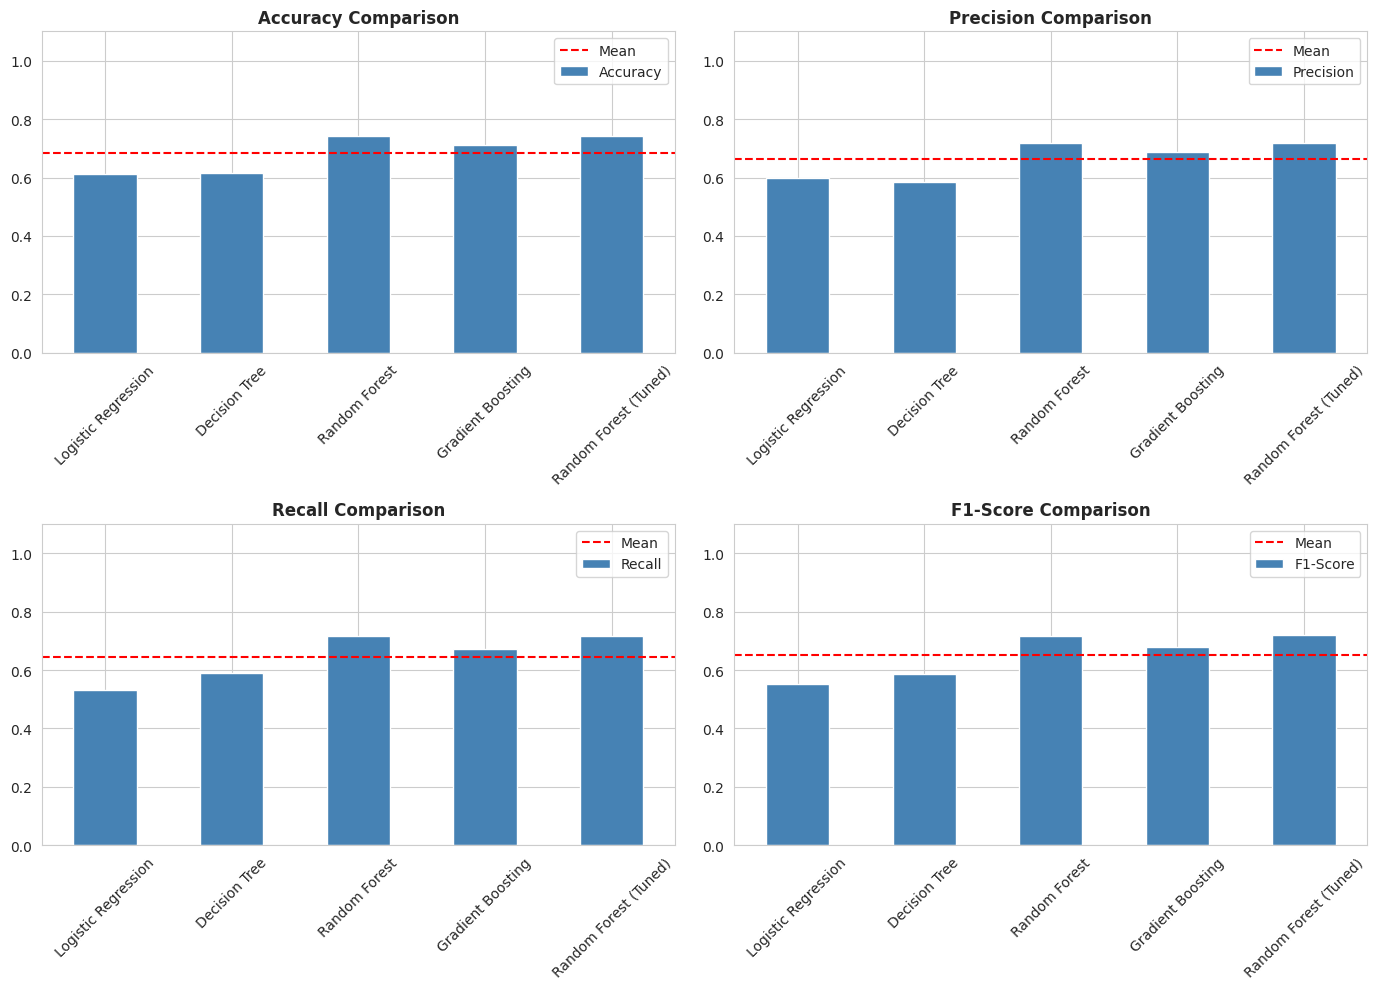

In [9]:
analyzer.plot_comparison()

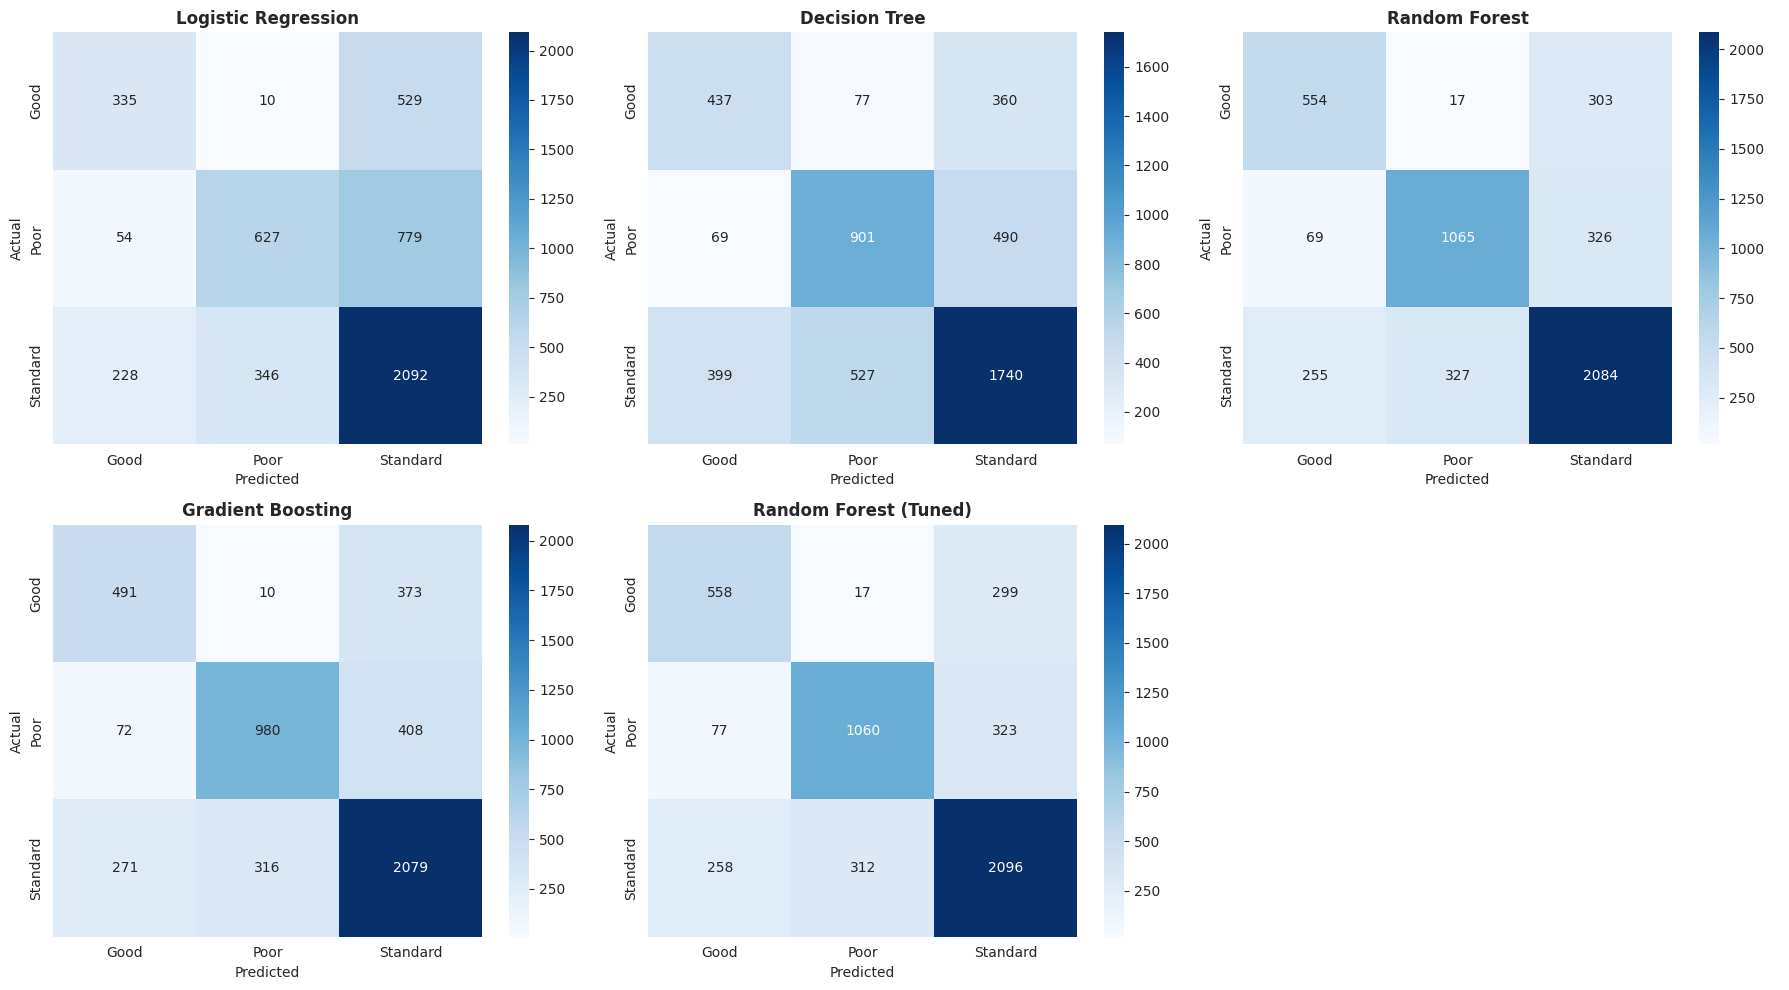

In [10]:
analyzer.plot_confusion_matrices()

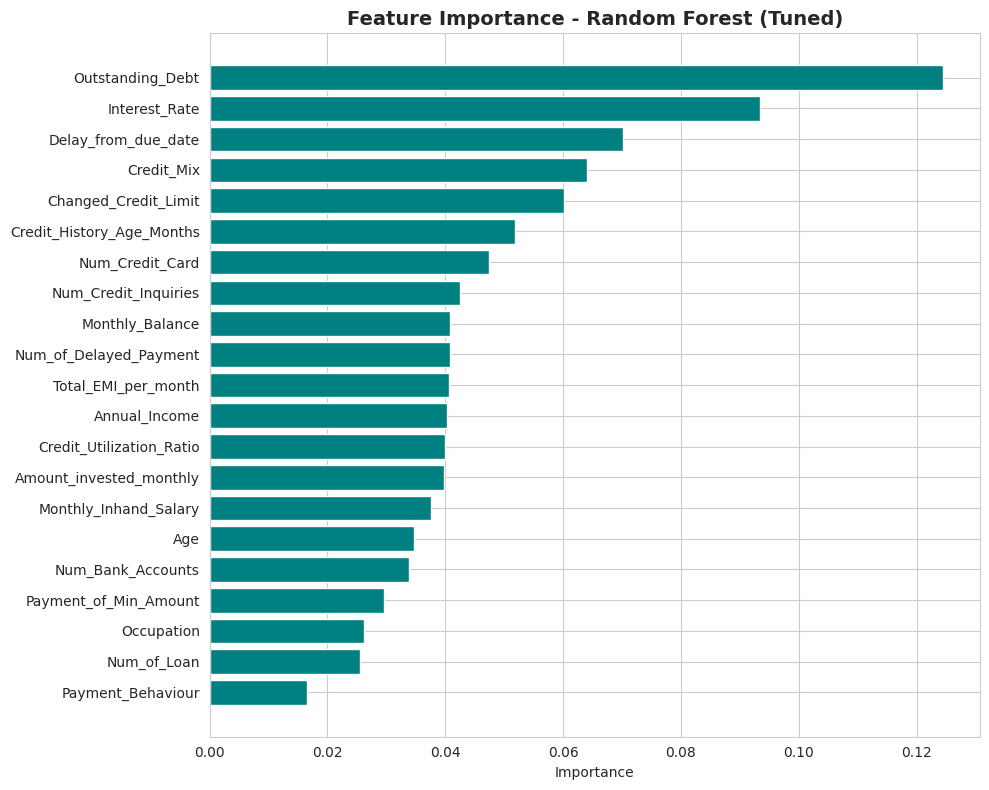


Top 5 features:
                 Feature  Importance
13      Outstanding_Debt    0.124536
6          Interest_Rate    0.093354
8    Delay_from_due_date    0.070184
12            Credit_Mix    0.063999
10  Changed_Credit_Limit    0.060229


In [11]:
fi_df = analyzer.plot_feature_importance('Random Forest (Tuned)')
print("\nTop 5 features:")
print(fi_df.head())

In [12]:
best_name = analyzer.report_best_model()


BEST MODEL: Random Forest (Tuned)
Accuracy    : 0.7428
Precision   : 0.7197
Recall      : 0.7169
F1-Score    : 0.7181

Classification Report:
              precision    recall  f1-score   support

        Good       0.62      0.64      0.63       874
        Poor       0.76      0.73      0.74      1460
    Standard       0.77      0.79      0.78      2666

    accuracy                           0.74      5000
   macro avg       0.72      0.72      0.72      5000
weighted avg       0.74      0.74      0.74      5000



## 6. Save Best Model

The notebook's best model is saved for reference. The production model used by the app is trained by `pipeline/run_pipeline.py` as a single sklearn Pipeline.

In [13]:
# ========================================
# 6. SAVE BEST MODEL & ARTIFACTS
# ========================================
artifacts = {
    'model': experimenter.fitted_models[best_name],
    'scaler': experimenter.scaler,
    'label_encoders': experimenter.label_encoders,
    'target_encoder': experimenter.target_encoder,
    'feature_columns': experimenter.feature_columns,
}

with open('credit_score_model_from_notebook.pkl', 'wb') as f:
    pickle.dump(artifacts, f)

print(f"Best model saved: {best_name}")
print(f"Artifacts       : credit_score_model_from_notebook.pkl")
print(f"\nProduction model (sklearn Pipeline) -> ../models/credit_score_pipeline.pkl")

Best model saved: Random Forest (Tuned)
Artifacts       : credit_score_model_from_notebook.pkl

Production model (sklearn Pipeline) -> ../models/credit_score_pipeline.pkl


## Conclusions

**Experiments**
1. **4 baseline models** compared (LR, DT, RF, GB)
2. **Hyperparameter tuning** of Random Forest with GridSearchCV (3-fold, macro-F1)
3. **Multiclass evaluation** with macro-averaged accuracy / precision / recall / F1

**Best model:** tuned Random Forest — highest macro-F1.

**Why macro-F1?** The target is imbalanced (Good is only ~17%), so accuracy can be misleading.
Macro-F1 weights every class equally, so performance on the minority class still counts.

**Feature importance** ranks `Outstanding_Debt`, `Interest_Rate`, `Credit_Mix` and `Credit_History_Age_Months`
among the most influential features, consistent with the EDA.